# 06. Olhos fechados

O baseline acerta bem onde ficam os pontos, mas tem um defeito sério para detectar sonolência:
ele **desenha quase sempre um olho meio aberto**. Na validação, só 18 % dos olhos fechados saem com
EAR abaixo de 0,15, e o EAR previsto dos olhos fechados fica em 0,19, quase o de um olho
semiaberto.

Neste notebook comparamos várias ideias para corrigir isso e escolhemos o modelo final.

1. As variantes treinadas e o que cada uma muda
2. Todas avaliadas na validação, com as mesmas medidas
3. O compromisso entre precisão geral e olhos fechados
4. As curvas de treino
5. A média com a face espelhada (TTA)
6. A escolha do modelo final
7. Olho aberto contra fechado: falsos positivos e curva ROC
8. Quanto dessas diferenças é ruído: sementes e ablação
9. O modelo final no teste do WFLW, comparado com o baseline
10. O modelo final num vídeo de webcam

Todas as variantes foram treinadas com o `train.py` e as configurações de `configs/`, numa GPU
RTX A6000 (cerca de 8 minutos cada). Os checkpoints ficam em `runs/fera/`. A escolha usa **só a
validação**; o teste entra uma única vez, no fim, para o modelo escolhido.

In [1]:
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import yaml
from torch import nn
from torch.nn import functional as F

plt.rcParams["figure.dpi"] = 90
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, PROCESSED, RUNS = ROOT / "data", ROOT / "data" / "processed", ROOT / "runs" / "fera"
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
RUN_NAMES = sorted(p.name for p in RUNS.iterdir() if (p / "best.pt").exists())
# repetições com outra semente e a ablação de épocas (015) vieram depois da escolha, só para conferir
REPLICAS = [r for r in RUN_NAMES if r.endswith(("_s1", "_s2")) or r.startswith("015")]
CANDIDATES = [r for r in RUN_NAMES if r not in REPLICAS]
print(DEVICE, len(RUN_NAMES), "variantes:", RUN_NAMES)

mps 20 variantes: ['001_baseline', '002_closed_eye_sampler', '003_eye_weight', '004_sampler_eye_weight', '005_opening_loss', '006_heatmap_reg', '006b_heatmap_reg_low', '007_wing', '008_004_heatmap', '009_004_opening', '010_strong_eyes', '010_strong_eyes_s1', '010_strong_eyes_s2', '011_004_heatmap_opening', '012_004_lowres', '013_final_strong_lowres', '013_final_strong_lowres_s1', '013_final_strong_lowres_s2', '014_final_strong_lowres_heatmap', '015_strong_eyes_80ep']


In [2]:
class LandmarkNet(nn.Module):
    # mesma rede do 03_modelo: ResNet-18 + cabeça de deconvoluções + soft-argmax
    def __init__(self, head_channels=256, num_deconv=3):
        super().__init__()
        resnet = torchvision.models.resnet18(weights=None)
        self.backbone = nn.Sequential(*list(resnet.children())[:-2])
        layers, c_in = [], 512
        for _ in range(num_deconv):
            layers += [nn.ConvTranspose2d(c_in, head_channels, 4, stride=2, padding=1, bias=False),
                       nn.BatchNorm2d(head_channels), nn.ReLU(inplace=True)]
            c_in = head_channels
        layers.append(nn.Conv2d(head_channels, 98, 1))
        self.head = nn.Sequential(*layers)
        self.stride = 32 // (2 ** num_deconv)

    def forward(self, x):
        logits = self.head(self.backbone(x))
        b, k, h, w = logits.shape
        prob = F.softmax(logits.reshape(b, k, -1).float(), -1).reshape(b, k, h, w)
        xs = torch.arange(w, device=x.device, dtype=prob.dtype)
        ys = torch.arange(h, device=x.device, dtype=prob.dtype)
        xy = torch.stack([(prob.sum(2) * xs).sum(-1), (prob.sum(3) * ys).sum(-1)], -1)
        return xy * self.stride + (self.stride - 1) / 2


def load(run):
    ckpt = torch.load(RUNS / run / "best.pt", map_location="cpu", weights_only=False)
    mc = ckpt["config"]["model"]
    model = LandmarkNet(mc["head_channels"], mc["num_deconv"])
    model.load_state_dict(ckpt["model"])
    return model.eval().to(DEVICE), ckpt


MEAN, STD = np.array([0.485, 0.456, 0.406], np.float32), np.array([0.229, 0.224, 0.225], np.float32)
MIRROR = np.array((DATA / "WFLW_annotations" / "Mirror98.txt").read_text().strip().split(","), dtype=int)


@torch.no_grad()
def predict(model, crops, tta=False, batch=64):
    # crops: (N, 256, 256, 3) uint8 RGB -> (N, 98, 2) em pixels do recorte
    out = []
    for s in range(0, len(crops), batch):
        x = torch.from_numpy(((crops[s:s + batch] / 255.0 - MEAN) / STD).transpose(0, 3, 1, 2).astype(np.float32)).to(DEVICE)
        p = model(x).float().cpu().numpy()
        if tta:   # média com a previsão da face espelhada, desfazendo o espelhamento
            q = model(torch.flip(x, dims=[3])).float().cpu().numpy()
            q[..., 0] = crops.shape[2] - 1 - q[..., 0]
            p = (p + q[:, MIRROR]) / 2
        out.append(p)
    return np.concatenate(out).astype(np.float64)

In [3]:
EAR_RIGHT, EAR_LEFT = (60, 61, 63, 64, 65, 67), (72, 71, 69, 68, 75, 73)
EYES = list(range(60, 76))


def ear(p):
    def one(idx):
        p1, p2, p3, p4, p5, p6 = (p[..., i, :] for i in idx)
        n = lambda a, b: np.linalg.norm(a - b, axis=-1)
        return (n(p2, p6) + n(p3, p5)) / (2 * n(p1, p4) + 1e-9)
    return (one(EAR_RIGHT) + one(EAR_LEFT)) / 2


def nme(pred, gt, points=None):
    e = np.linalg.norm(pred - gt, axis=-1) / np.linalg.norm(gt[:, 60] - gt[:, 72], axis=-1)[:, None]
    return e.mean(-1) if points is None else e[:, points].mean(-1)


def measures(pred, gt):
    e_gt, e_pred = ear(gt), ear(pred)
    closed = e_gt < 0.15
    return {"NME (%)": 100 * nme(pred, gt).mean(),
            "falha (%)": 100 * (nme(pred, gt) > 0.1).mean(),
            "NME olhos (%)": 100 * nme(pred, gt, EYES).mean(),
            "corr. EAR": np.corrcoef(e_gt, e_pred)[0, 1],
            "inclinação EAR": np.polyfit(e_gt, e_pred, 1)[0],
            "EAR prev. fechados": e_pred[closed].mean(),
            "fechados reconhecidos (%)": 100 * (e_pred[closed] < 0.15).mean()}

## 1. As variantes

Cada variante muda poucas coisas em relação ao baseline. Elas atacam três causas diferentes do
"olho médio aberto":

- **Poucos exemplos de olho fechado** (só cerca de 9 % do treino): sobreamostrar as faces com EAR
  anotado abaixo de 0,15 com o `WeightedRandomSampler`.
- **A perda quase não liga para a pálpebra:** errar 1 ou 2 pixels entre as pálpebras, em 16 de 98
  pontos, mal muda a L1. Por isso testamos dar mais peso aos pontos 60 a 75, um termo
  que compara a **abertura** prevista do olho com a anotada, e a Wing loss, que dá mais peso aos
  erros pequenos.
- **Mapas de calor espalhados:** sem nada que os obrigue a ter um pico, os mapas ficam largos e o
  soft-argmax vira uma média que puxa a pálpebra para o meio. A regularização dos mapas aproxima
  cada mapa de uma gaussiana estreita no ponto certo (como no DSNT).

Por fim, um augmentation de **baixa resolução** (reduzir o recorte de 2 a 4 vezes e ampliar de
volta) imita as faces pequenas de webcam.

In [4]:
def describe(cfg):
    a, l, s = cfg["augment"], cfg["loss"], cfg.get("sampler", {})
    parts = []
    if s.get("closed_eye_weight", 1) != 1: parts.append(f"sobreamostragem ×{s['closed_eye_weight']:g}")
    if l.get("eye_weight", 1) != 1: parts.append(f"peso olhos {l['eye_weight']:g}")
    if l.get("opening_weight", 0): parts.append(f"abertura {l['opening_weight']:g}")
    if l.get("heatmap_weight", 0): parts.append(f"mapas {l['heatmap_weight']:g}")
    if l["kind"] != "l1": parts.append(l["kind"])
    if a.get("lowres_prob", 0): parts.append("baixa resolução")
    parts.append(f"{cfg['train']['epochs']} épocas")
    return ", ".join(parts)


configs = {r: yaml.safe_load((RUNS / r / "config.yaml").read_text()) for r in RUN_NAMES}
pd.DataFrame({"o que muda": {r: describe(c) for r, c in configs.items()}})

,o que muda
001_baseline,40 épocas
002_closed_eye_sampler,"sobreamostragem ×4, 40 épocas"
003_eye_weight,"peso olhos 4, 40 épocas"
004_sampler_eye_weight,"sobreamostragem ×4, peso olhos 4, 40 épocas"
005_opening_loss,"abertura 1, 40 épocas"
006_heatmap_reg,"mapas 1, 40 épocas"
006b_heatmap_reg_low,"mapas 0.1, 40 épocas"
007_wing,"wing, 40 épocas"
008_004_heatmap,"sobreamostragem ×4, peso olhos 4, mapas 1, 40 ..."
009_004_opening,"sobreamostragem ×4, peso olhos 4, abertura 0.1..."


## 2. Todas as variantes na validação

Carregamos o melhor checkpoint de cada variante e medimos as 763 faces de validação (62 delas com
olhos fechados) com as mesmas medidas. Além do NME, olhamos o que importa para a sonolência:

- **corr. EAR:** o quanto o EAR previsto acompanha o anotado;
- **inclinação EAR:** a inclinação da reta entre EAR previsto e anotado; 1 seria o ideal, e valores
  menores mostram que o modelo puxa o EAR para a média;
- **EAR prev. fechados:** o EAR médio previsto quando o olho está fechado (o anotado é cerca de 0,09);
- **fechados reconhecidos:** a fração dos olhos fechados que sai com EAR abaixo de 0,15.

In [5]:
split = np.load(PROCESSED / "split.npz")
crops_tr = np.load(PROCESSED / "train_crops.npy", mmap_mode="r")
meta_tr = np.load(PROCESSED / "train_meta.npz")
OFF = (384 - 256) // 2
val_idx = split["val_idx"]
val_crops = np.stack([np.asarray(crops_tr[k])[OFF:OFF + 256, OFF:OFF + 256] for k in val_idx])
val_gt = meta_tr["landmarks"][val_idx].astype(np.float64) - OFF

val = {}
for r in RUN_NAMES:
    model, ckpt = load(r)
    val[r] = measures(predict(model, val_crops), val_gt)
table = pd.DataFrame(val).T
table.style.format("{:.2f}").format("{:.3f}", subset=["corr. EAR", "EAR prev. fechados"]) \
    .background_gradient(cmap="Greens", subset=["fechados reconhecidos (%)", "corr. EAR"]) \
    .background_gradient(cmap="Greens_r", subset=["NME (%)", "NME olhos (%)"])

,NME (%),falha (%),NME olhos (%),corr. EAR,inclinação EAR,EAR prev. fechados,fechados reconhecidos (%)
001_baseline,4.13,2.88,2.87,0.650,0.48,0.190,17.74
002_closed_eye_sampler,4.16,2.75,2.83,0.678,0.60,0.158,41.94
003_eye_weight,4.17,2.75,2.65,0.719,0.62,0.163,35.48
004_sampler_eye_weight,4.22,2.49,2.65,0.714,0.68,0.138,59.68
005_opening_loss,5.32,6.29,6.37,0.756,0.66,0.133,53.23
006_heatmap_reg,4.01,1.97,2.76,0.679,0.54,0.177,17.74
006b_heatmap_reg_low,4.03,1.83,2.76,0.588,0.53,0.183,19.35
007_wing,4.10,2.49,2.83,0.605,0.48,0.197,11.29
008_004_heatmap,4.02,2.10,2.67,0.708,0.64,0.145,46.77
009_004_opening,4.24,2.49,2.65,0.746,0.63,0.136,61.29


## 3. Precisão geral contra olhos fechados

Cada ponto é uma variante. O ideal é ficar no canto de baixo à direita: NME baixo e muitos olhos
fechados reconhecidos.

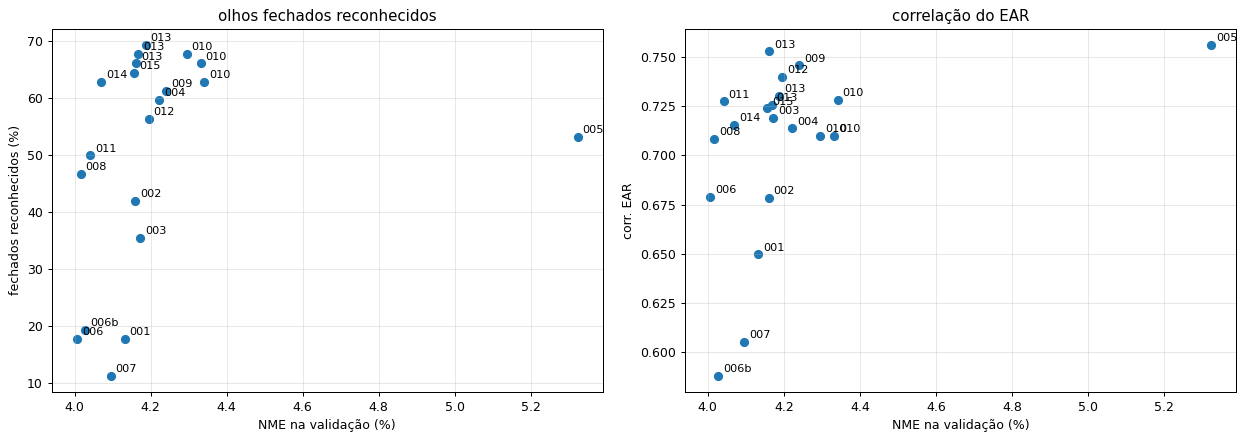

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, ycol in zip(axes, ["fechados reconhecidos (%)", "corr. EAR"]):
    ax.scatter(table["NME (%)"], table[ycol], s=40)
    for r, row in table.iterrows():
        ax.annotate(r.split("_")[0], (row["NME (%)"], row[ycol]), xytext=(4, 3), textcoords="offset points", fontsize=9)
    ax.set_xlabel("NME na validação (%)"); ax.set_ylabel(ycol); ax.grid(alpha=0.3)
axes[0].set_title("olhos fechados reconhecidos"); axes[1].set_title("correlação do EAR")
plt.tight_layout(); plt.show()

O que dá para ler:

- **Sobreamostragem e peso nos olhos** (002, 003, 004, 010) são o que mais ajuda nos olhos
  fechados, e o efeito cresce quando os dois são usados juntos e com mais força.
- **A perda de abertura com peso 1 (005)** melhora o EAR, mas estraga a posição dos pontos (o NME
  sobe para mais de 5 %): o termo dominou a perda. Com peso 0,1 (009) ele deixa de atrapalhar.
- **A regularização dos mapas** (006, 008) melhora a precisão geral (o menor NME), mas sozinha não
  resolve os olhos fechados.
- **Wing loss** (007) não ajudou nos olhos.

## 4. Curvas de treino

A correlação do EAR e o EAR previsto nos olhos fechados ao longo das épocas, para o baseline e para
as variantes mais fortes. As variantes antigas (001 e 002) foram treinadas antes de registrarmos as
medidas dos olhos fechados por época, então aparecem só no primeiro gráfico.

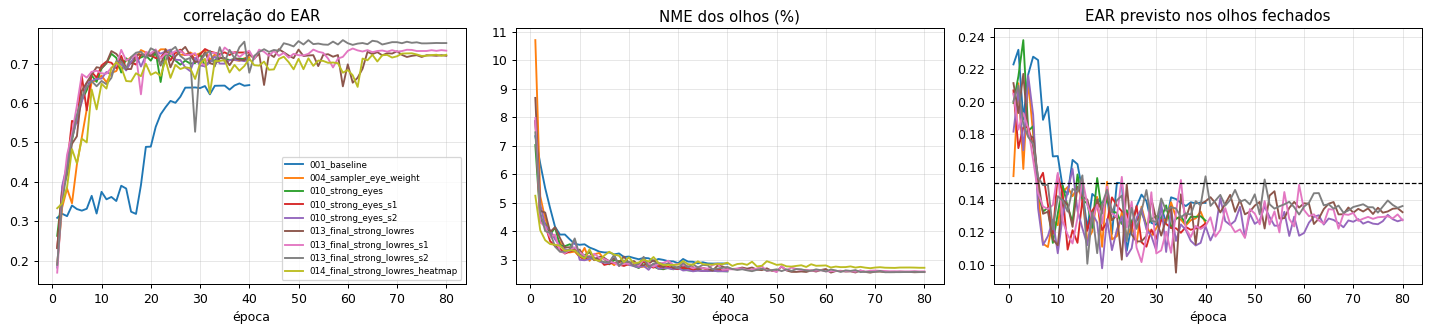

In [7]:
show = [r for r in RUN_NAMES if r.split("_")[0] in ("001", "004", "010", "013", "014")]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for r in show:
    log = pd.read_csv(RUNS / r / "log.csv")
    axes[0].plot(log["epoch"], log["val_ear_corr"], label=r)
    axes[1].plot(log["epoch"], 100 * log["val_eye_nme"], label=r)
    if "val_closed_ear_pred" in log:
        axes[2].plot(log["epoch"], log["val_closed_ear_pred"], label=r)
axes[0].set_title("correlação do EAR"); axes[1].set_title("NME dos olhos (%)")
axes[2].set_title("EAR previsto nos olhos fechados"); axes[2].axhline(0.15, c="k", ls="--", lw=1)
for ax in axes:
    ax.set_xlabel("época"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 5. Média com a face espelhada (TTA)

Uma ideia que não exige treinar nada: prever a face normal e a face espelhada, desfazer o
espelhamento na segunda (com o `Mirror98`) e tirar a média dos pontos. Os erros das duas previsões
não são iguais, então a média tem menos ruído. O custo é rodar a rede duas vezes por face.

In [8]:
tta = {}
for r in [n for n in RUN_NAMES if n.split("_")[0] in ("001", "004", "010", "013", "014")]:
    model, _ = load(r)
    tta[(r, "sem TTA")] = val[r]
    tta[(r, "com TTA")] = measures(predict(model, val_crops, tta=True), val_gt)
pd.DataFrame(tta).T.style.format("{:.3f}")

O TTA melhora o NME, o NME dos olhos e a correlação do EAR em todos os modelos testados, então ele
fica **ligado** no `predict.py` e no `app.py`. Ele quase não muda a inclinação nem a fração de olhos
fechados reconhecidos (no baseline essa fração até cai um pouco), então as comparações de seleção
são feitas **sem** TTA, e o teste e a aplicação usam TTA.

## 6. A escolha do modelo final

A regra usa só a validação: entre as variantes cujo NME fica no máximo 0,2 ponto acima do baseline
(para não piorar a qualidade dos landmarks), escolhemos a que reconhece **mais olhos
fechados**; em caso de empate, a de maior correlação do EAR.

Uma observação honesta: no report do baseline o critério previsto era a **correlação do EAR**.
Trocamos para a fração de olhos fechados reconhecidos porque é ela que decide se o alerta acontece.
Pela correlação, a escolhida seria a 009 (0,746 contra 0,725), uma diferença que, como mostra a
seção 8, fica dentro da variação entre execuções.

In [9]:
base_nme = table.loc[[r for r in table.index if r.startswith("001")][0], "NME (%)"]
pool = table.loc[CANDIDATES]
ok = pool[pool["NME (%)"] <= base_nme + 0.2]
FINAL = ok.sort_values(["fechados reconhecidos (%)", "corr. EAR"], ascending=False).index[0]
BASE = [r for r in RUN_NAMES if r.startswith("001")][0]
print(f"NME do baseline: {base_nme:.2f} % | limite: {base_nme + 0.2:.2f} %")
print("candidatas dentro do limite:", list(ok.index))
print("modelo final:", FINAL, "|", describe(configs[FINAL]))

NME do baseline: 4.13 % | limite: 4.33 %
candidatas dentro do limite: ['001_baseline', '002_closed_eye_sampler', '003_eye_weight', '004_sampler_eye_weight', '006_heatmap_reg', '006b_heatmap_reg_low', '007_wing', '008_004_heatmap', '009_004_opening', '010_strong_eyes', '011_004_heatmap_opening', '012_004_lowres', '013_final_strong_lowres', '014_final_strong_lowres_heatmap']
modelo final: 013_final_strong_lowres | sobreamostragem ×8, peso olhos 8, baixa resolução, 80 épocas


## 7. Olho aberto contra fechado: falsos positivos e curva ROC

Reconhecer mais olhos fechados só vale se o modelo não passar a marcar olhos abertos como fechados.
Tratando "olho fechado" (EAR anotado abaixo de 0,15) como uma classificação em que o EAR previsto é
a nota, a **curva ROC** mostra os dois erros juntos para todos os limiares, e a **área sob a curva
(AUC)** resume o quanto o EAR previsto separa olho aberto de fechado, sem depender do limiar. O
intervalo de 95 % vem de 1.000 reamostragens (bootstrap) da validação.

,AUC,"AUC 2,5 %","AUC 97,5 %",fechados reconhecidos (%),abertos marcados como fechados (%)
001_baseline,0.859,0.796,0.916,17.742,0.571
004_sampler_eye_weight,0.909,0.870,0.945,59.677,5.136
009_004_opening,0.912,0.868,0.951,61.290,3.566
010_strong_eyes,0.909,0.859,0.945,67.742,6.277
013_final_strong_lowres,0.900,0.848,0.943,67.742,5.849
014_final_strong_lowres_heatmap,0.909,0.860,0.947,62.903,4.850


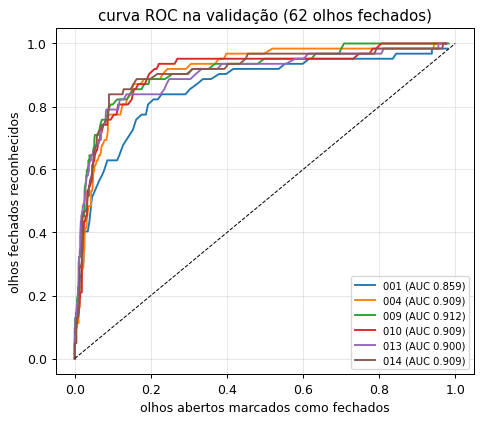

In [10]:
def auc(score_closed, score_open):
    # probabilidade de um olho fechado ter EAR previsto menor que um olho aberto
    s = np.concatenate([score_closed, score_open])
    ranks = pd.Series(s).rank().to_numpy()
    n1, n0 = len(score_closed), len(score_open)
    return (n1 * n0 + n1 * (n1 + 1) / 2 - ranks[:n1].sum()) / (n1 * n0)


e_val = ear(val_gt)
is_closed = e_val < 0.15
rng = np.random.default_rng(0)
roc_rows, curves_roc = {}, {}
for r in [n for n in CANDIDATES if n.split("_")[0] in ("001", "004", "009", "010", "013", "014")]:
    ep = ear(predict(load(r)[0], val_crops))
    boot = []
    for _ in range(1000):
        i = rng.integers(0, len(ep), len(ep))
        boot.append(auc(ep[i][is_closed[i]], ep[i][~is_closed[i]]))
    roc_rows[r] = {"AUC": auc(ep[is_closed], ep[~is_closed]),
                   "AUC 2,5 %": np.percentile(boot, 2.5), "AUC 97,5 %": np.percentile(boot, 97.5),
                   "fechados reconhecidos (%)": 100 * (ep[is_closed] < 0.15).mean(),
                   "abertos marcados como fechados (%)": 100 * (ep[~is_closed] < 0.15).mean()}
    th = np.linspace(0, 0.4, 200)
    curves_roc[r] = ([(ep[~is_closed] < x).mean() for x in th], [(ep[is_closed] < x).mean() for x in th])
display(pd.DataFrame(roc_rows).T.round(3))

fig, ax = plt.subplots(figsize=(6, 5))
for r, (fpr, tpr) in curves_roc.items():
    ax.plot(fpr, tpr, label=f"{r.split('_')[0]} (AUC {roc_rows[r]['AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlabel("olhos abertos marcados como fechados"); ax.set_ylabel("olhos fechados reconhecidos")
ax.set_title("curva ROC na validação (62 olhos fechados)"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()

O que a curva mostra:

- as variantes com tratamento para os olhos separam aberto de fechado melhor que o baseline (AUC
  de 0,90 a 0,91 contra 0,86) e, no limiar de 0,15, reconhecem de 3 a 4 vezes mais olhos fechados;
  como a validação tem só 62 olhos fechados, os intervalos da AUC ainda se encostam;
- entre elas, as AUCs são parecidas e os intervalos se sobrepõem: o que mais muda de uma para outra
  é **onde** o EAR previsto fica, e não o quanto ele separa. O 013 reconhece mais olhos fechados no
  limiar fixo de 0,15 em parte porque desloca o EAR para baixo, e paga isso com mais olhos abertos
  marcados como fechados;
- na aplicação o limiar não é 0,15 fixo, e sim 0,7 vezes o EAR típico da própria pessoa
  (`08_aplicacao_video`), o que compensa esse deslocamento.

## 8. Quanto dessas diferenças é ruído: sementes e ablação

Cada variante foi treinada uma vez, e a validação tem só 62 olhos fechados (cada olho vale 1,6
ponto na fração reconhecida). Para separar o que é real do que é sorte, treinamos de novo a 010 e a
013 com outras duas sementes (a divisão treino/validação continua a mesma), e treinamos a 010 com
80 épocas (015), para separar o efeito das épocas do efeito do augmentation de baixa resolução.

In [11]:
for r in REPLICAS:          # mede as repetições com as mesmas medidas da seção 2
    if r not in val:
        val[r] = measures(predict(load(r)[0], val_crops), val_gt)
cols = ["NME (%)", "NME olhos (%)", "corr. EAR", "fechados reconhecidos (%)"]
groups = {"010 (40 épocas)": ["010_strong_eyes", "010_strong_eyes_s1", "010_strong_eyes_s2"],
          "013 (80 épocas, baixa resolução)": ["013_final_strong_lowres", "013_final_strong_lowres_s1", "013_final_strong_lowres_s2"]}
rows = {}
for g, names in groups.items():
    m = pd.DataFrame({n: val[n] for n in names if n in val}).T[cols]
    rows[f"{g}: {len(m)} sementes"] = {c: f"{m[c].mean():.2f} ± {m[c].std():.2f}" for c in cols}
pd.DataFrame(rows).T

,NME (%),NME olhos (%),corr. EAR,fechados reconhecidos (%)
010 (40 épocas): 3 sementes,4.32 ± 0.02,2.61 ± 0.02,0.72 ± 0.01,65.59 ± 2.46
"013 (80 épocas, baixa resolução): 3 sementes",4.17 ± 0.01,2.57 ± 0.02,0.74 ± 0.01,67.74 ± 1.61


In [12]:
steps = [("baseline", "001_baseline"), ("+ sobreamostragem ×4 e peso 4 nos olhos", "004_sampler_eye_weight"),
         ("reforço para ×8 e peso 8", "010_strong_eyes"), ("+ 80 épocas", "015_strong_eyes_80ep"),
         ("+ baixa resolução (013)", "013_final_strong_lowres")]
pd.DataFrame({lab: val[r] for lab, r in steps if r in val}).T[
    ["NME (%)", "NME olhos (%)", "corr. EAR", "inclinação EAR", "EAR prev. fechados", "fechados reconhecidos (%)"]].round(3)

,NME (%),NME olhos (%),corr. EAR,inclinação EAR,EAR prev. fechados,fechados reconhecidos (%)
baseline,4.132,2.874,0.650,0.483,0.190,17.742
+ sobreamostragem ×4 e peso 4 nos olhos,4.222,2.651,0.714,0.678,0.138,59.677
reforço para ×8 e peso 8,4.295,2.598,0.710,0.683,0.125,67.742
+ 80 épocas,4.156,2.559,0.724,0.686,0.132,64.516
+ baixa resolução (013),4.168,2.554,0.725,0.711,0.127,67.742


Como ler, comparando com a variação entre sementes da tabela anterior:

- **sair do baseline** para as variantes com tratamento dos olhos é de longe o maior ganho: a fração
  de olhos fechados reconhecidos vai de 18 % para 60 % a 68 %, e isso aparece em todas as sementes;
- **mais épocas** (40 para 80) melhora o NME geral de forma consistente: 4,32 ± 0,02 % nas três
  sementes da 010 contra 4,17 ± 0,01 % nas três da 013, uma diferença bem maior que a variação
  entre sementes. É isso que traz o NME do modelo final de volta para perto do baseline;
- a **baixa resolução** quase não muda as medidas da validação (015 contra 013); o efeito que
  esperávamos dela é em vídeo de webcam, com face pequena, que o WFLW não representa bem;
- a fração de olhos fechados reconhecidos fica entre 63 % e 71 % nas sementes da 010 e da 013, então
  essas variantes **empatam** nesse ponto. Por isso dizemos que a 013 foi escolhida **pela regra**,
  e que a vantagem comprovada dela sobre a 010 é o NME geral, não os olhos fechados.

## 9. O modelo final no teste do WFLW

Agora sim usamos o teste oficial (2.500 faces), uma única vez, comparando o modelo escolhido com o
baseline, os dois com TTA.

In [13]:
crops_te = np.load(PROCESSED / "test_crops.npy", mmap_mode="r")
meta_te = np.load(PROCESSED / "test_meta.npz")
test_crops = np.stack([np.asarray(c)[OFF:OFF + 256, OFF:OFF + 256] for c in crops_te])
test_gt = meta_te["landmarks"].astype(np.float64) - OFF
attrs = meta_te["attributes"]
ATTR = ["pose", "expressão", "iluminação", "maquiagem", "oclusão", "desfoque"]

test_pred, test_res = {}, {}
for r in (BASE, FINAL):
    model, _ = load(r)
    test_pred[r] = predict(model, test_crops, tta=True)
    m = measures(test_pred[r], test_gt)
    per_face = nme(test_pred[r], test_gt)
    m.update({f"NME {a} (%)": 100 * per_face[attrs[:, j] == 1].mean() for j, a in enumerate(ATTR)})
    test_res[r] = m
pd.DataFrame(test_res).style.format("{:.3f}")

,001_baseline,013_final_strong_lowres
NME (%),5.050,5.122
falha (%),6.080,6.680
NME olhos (%),3.529,3.269
corr. EAR,0.644,0.725
inclinação EAR,0.446,0.645
EAR prev. fechados,0.188,0.127
fechados reconhecidos (%),23.358,67.518
NME pose (%),9.129,9.221
NME expressão (%),5.445,5.531
NME iluminação (%),4.930,5.052


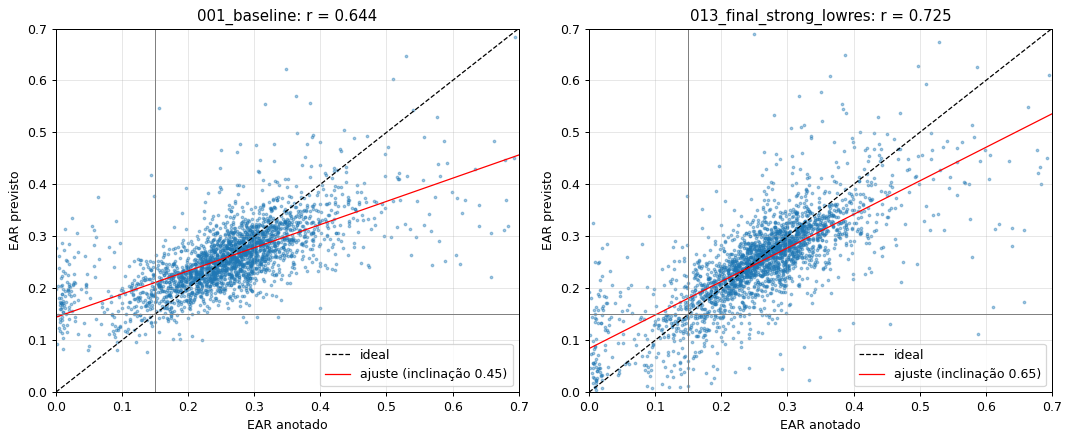

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
e_gt = ear(test_gt)
for ax, r in zip(axes, (BASE, FINAL)):
    e_pred = ear(test_pred[r])
    a, b = np.polyfit(e_gt, e_pred, 1)
    ax.scatter(e_gt, e_pred, s=4, alpha=0.4)
    ax.plot([0, 0.7], [0, 0.7], "k--", lw=1, label="ideal")
    ax.plot([0, 0.7], [b, 0.7 * a + b], "r-", lw=1, label=f"ajuste (inclinação {a:.2f})")
    ax.axvline(0.15, c="gray", lw=0.8); ax.axhline(0.15, c="gray", lw=0.8)
    ax.set_xlim(0, 0.7); ax.set_ylim(0, 0.7); ax.set_xlabel("EAR anotado"); ax.set_ylabel("EAR previsto")
    ax.set_title(f"{r}: r = {np.corrcoef(e_gt, e_pred)[0, 1]:.3f}"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

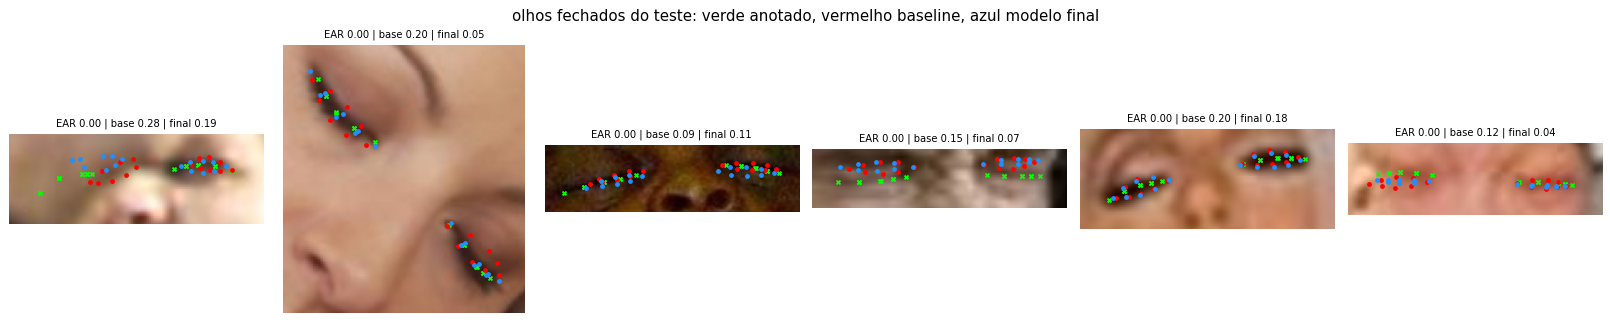

In [15]:
# olhos mais fechados do teste: anotado (verde), baseline (vermelho) e modelo final (azul)
order = np.argsort(e_gt)[:6]
fig, axes = plt.subplots(1, 6, figsize=(18, 3.6))
for ax, k in zip(axes, order):
    g = test_gt[k]
    x0, y0 = g[60:76].min(0) - 14
    x1, y1 = g[60:76].max(0) + 14
    ax.imshow(test_crops[k])
    ax.scatter(*g[60:76].T, s=10, c="lime", marker="x")
    ax.scatter(*test_pred[BASE][k][60:76].T, s=8, c="red")
    ax.scatter(*test_pred[FINAL][k][60:76].T, s=8, c="dodgerblue")
    ax.set_xlim(x0, x1); ax.set_ylim(y1, y0); ax.axis("off")
    ax.set_title(f"EAR {e_gt[k]:.2f} | base {ear(test_pred[BASE][k]):.2f} | final {ear(test_pred[FINAL][k]):.2f}", fontsize=8)
plt.suptitle("olhos fechados do teste: verde anotado, vermelho baseline, azul modelo final")
plt.tight_layout(); plt.show()

## 10. O modelo final num vídeo de webcam

Um vídeo de 33 segundos gravado com a webcam de um notebook, sem nada desenhado na imagem, com este
roteiro: olhos abertos, piscadas, um fechamento de cerca de 2,5 s (de 3,8 a 6,3 s), a cabeça virada
para o lado (de 9 a 11 s), um fechamento de cerca de 2 s com a cabeça virada (de 12,8 a 15,1 s),
uma piscada de um olho só (perto de 17 s) e mais piscadas.

Rodamos o caminho completo da aplicação (YuNet, recorte, modelo com TTA, EAR médio dos dois olhos)
em cada frame e comparamos o EAR do baseline com o do modelo final. Os limiares seguem o `app.py`:
a mediana dos 3 primeiros segundos vezes 0,7. O vídeo não é publicado aqui; mostramos só as curvas.

> Por que um vídeo cru? Um vídeo de referência que testamos antes era a **saída** de outro sistema,
> com os landmarks dele desenhados em verde sobre cada frame, inclusive em volta dos olhos. Esses
> pontos entram no recorte e confundem o modelo, então um vídeo assim não serve como entrada para
> medir o EAR.

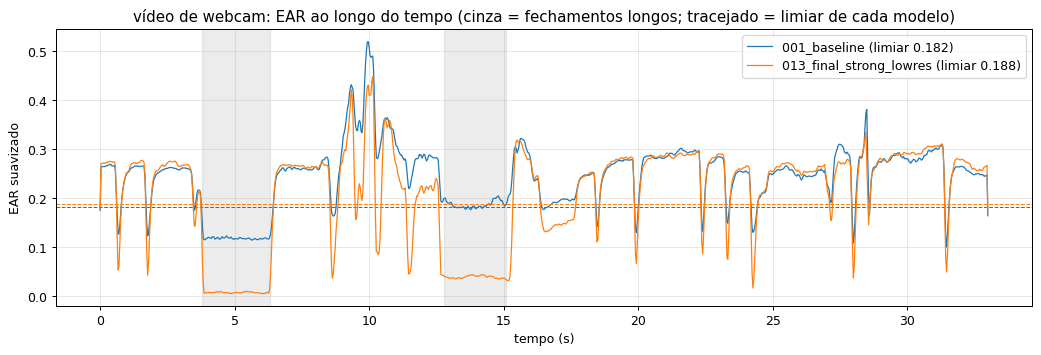

001_baseline: EAR típico 0.260 | fechamento de frente 0.118 | fechamento com a cabeça virada 0.184 | limiar 0.182
013_final_strong_lowres: EAR típico 0.268 | fechamento de frente 0.008 | fechamento com a cabeça virada 0.039 | limiar 0.188


In [16]:
VIDEO = ROOT.parent / "videos" / "teste_webcam.mov"
yunet = cv2.FaceDetectorYN.create(str(ROOT / "models" / "face_detection_yunet_2023mar.onnx"), "", (320, 320), 0.6, 0.3, 5000)


def crop_matrix(box, size=256, margin=1.25):
    x0, y0, x1, y1 = box
    c = np.array([(x0 + x1) / 2, (y0 + y1) / 2])
    s = size / (margin * max(x1 - x0, y1 - y0))
    return np.array([[s, 0, size / 2 - s * c[0]], [0, s, size / 2 - s * c[1]]])


def video_ear(run):
    model, _ = load(run)
    cap = cv2.VideoCapture(str(VIDEO))
    fps = cap.get(cv2.CAP_PROP_FPS)
    t, e = [], []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        h, w = frame.shape[:2]
        s = 640 / max(h, w)
        small = cv2.resize(frame, None, fx=s, fy=s)
        yunet.setInputSize((small.shape[1], small.shape[0]))
        _, faces = yunet.detect(small)
        if faces is None:
            continue
        f = max(faces, key=lambda f: f[2] * f[3])[:4] / s
        crop = cv2.warpAffine(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB), crop_matrix([f[0], f[1], f[0] + f[2], f[1] + f[3]]), (256, 256))
        p = predict(model, crop[None], tta=True)[0]
        t.append(len(t) / fps); e.append(ear(p[None])[0])
    e = np.convolve(e, np.ones(3) / 3, mode="same")     # mesma média móvel de 3 frames do app.py
    return np.array(t), e


if VIDEO.exists():
    curves = {r: video_ear(r) for r in (BASE, FINAL)}
    fig, ax = plt.subplots(figsize=(14, 4))
    for r, (t, e) in curves.items():
        base = np.median(e[t < 3]); line, = ax.plot(t, e, lw=1, label=f"{r} (limiar {0.7 * base:.3f})")
        ax.axhline(0.7 * base, c=line.get_color(), ls="--", lw=0.8)
    ax.set_xlabel("tempo (s)"); ax.set_ylabel("EAR suavizado"); ax.legend(); ax.grid(alpha=0.3)
    for a, b in [(3.8, 6.3), (12.8, 15.1)]:
        ax.axvspan(a, b, color="gray", alpha=0.15)
    ax.set_title("vídeo de webcam: EAR ao longo do tempo (cinza = fechamentos longos; tracejado = limiar de cada modelo)")
    plt.show()
    for r, (t, e) in curves.items():
        base = np.median(e[t < 3])
        c1, c2 = (t > 3.9) & (t < 6.2), (t > 12.9) & (t < 15.0)
        print(f"{r}: EAR típico {base:.3f} | fechamento de frente {np.median(e[c1]):.3f} | "
              f"fechamento com a cabeça virada {np.median(e[c2]):.3f} | limiar {0.7 * base:.3f}")
else:
    print("vídeo de teste não encontrado em", VIDEO)

## Conclusão

O modelo escolhido pela validação (013: sobreamostragem ×8 dos olhos fechados, peso 8 nos pontos
dos olhos, augmentation de baixa resolução e 80 épocas) é o que mais separa olho aberto de fechado:

- no teste do WFLW (com TTA), reconhece 67,5 % dos olhos fechados, contra 23,4 % do baseline, com
  NME dos olhos menor (3,27 % contra 3,53 %). O preço é pequeno, mas existe: o NME geral sobe 0,07
  ponto (5,05 % para 5,12 %), a taxa de falha vai de 6,1 % para 6,7 %, e todos os subconjuntos
  pioram cerca de 0,1 ponto;
- na webcam, o EAR típico é 0,268 com o olho aberto e cai para 0,008 de frente e 0,039 com a cabeça
  virada, enquanto o baseline só chega a 0,118 de frente e 0,184 virado, colado no limiar (0,182);
- entre as variantes com tratamento dos olhos, as diferenças são pequenas perto da variação entre
  sementes (seção 8); o ganho robusto é o de sair do baseline.

A avaliação completa do modelo final (pipeline com YuNet, regiões, exemplos e tempo) está no
`07_avaliacao_final`, e a escolha dos parâmetros da aplicação no `08_aplicacao_video`.

Ele passa a ser o `weights/modelo.pt` usado pelo `predict.py` e pelo `app.py`.